# Le Secret du Titan: which features find the matching installment?

Results from `compare_features.py` (re-run it after new features are computed; this notebook only reads its output).

**Main measure: progression.** For every installment we take its best match and ask whether the best matches
follow the order of the novel: the Spearman correlation between where an installment really is and where its
best match is. 1 = every installment found in the right order, 0 = random.

Also shown: **top-1** (share of installments whose best match is the right one) and, for the noise test,
**separation** (how far the right match stands out from all other candidates).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

features = Path("secret_du_titan/features")
comparison = pd.DataFrame(json.loads((features / "comparison.json").read_text()))
robustness = pd.DataFrame(json.loads((features / "robustness.json").read_text()))

# fixed colour + marker + line style per feature (identity never rests on colour alone)
STYLE = {
    "MFW":              dict(color="#2a78d6", marker="o", linestyle="-"),
    "passim":           dict(color="#eb6834", marker="s", linestyle="--"),
    "GTE histlux":      dict(color="#1baf7a", marker="^", linestyle="-."),
    "NER (name words)": dict(color="#e87ba4", marker="v", linestyle="-"),
    "NER (full names)": dict(color="#6250d6", marker="P", linestyle="-"),
    "GTE + NER":        dict(color="#eda100", marker="D", linestyle=":"),
}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.edgecolor": GRID, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11})

## 1. The text pairs

| pair | what it tests | right answer |
|---|---|---|
| fr vs fr_en_fr | French vs its round trip (FR→EN→FR, Google) | known: same installment |
| fr vs fr_en | French vs its English translation | known: same installment |
| de vs fr_de | real German (1891) vs Google's German of the French | approximate: same relative position, ±1 installment |
| **de vs fr** | **real German vs the French original: the real task** | approximate: same relative position, ±1 installment |

MFW and passim only work within one language. NER (Impresso's `ner-stacked-bert-multilingual`, names kept as
written, TF-IDF weighted) was only run on the two originals. *Name words* splits names into words, so
"landry" matches in "Pierre Landry" / "Peter Landry"; *full names* does not. *GTE + NER* averages the GTE and
NER (name words) similarities after standardising each.

In [2]:
ORDER = ["fr vs fr_en_fr", "fr vs fr_en", "de vs fr_de", "de vs fr"]
COLS = [c for c in STYLE if c in set(comparison["feature"])]
table = comparison.pivot_table(index="pair", columns="feature", values="progression").reindex(ORDER)[COLS]
print("progression (Spearman, 1 = best matches follow the novel); empty = feature not available for that pair")
table.round(2)

progression (Spearman, 1 = best matches follow the novel); empty = feature not available for that pair


feature,MFW,passim,GTE histlux,NER (name words),NER (full names),GTE + NER
pair,,,,,,
fr vs fr_en_fr,1.00,1.00,1.00,NaN,NaN,NaN
fr vs fr_en,NaN,NaN,1.00,NaN,NaN,NaN
de vs fr_de,0.72,0.92,0.81,NaN,NaN,NaN
de vs fr,NaN,NaN,0.83,0.72,0.62,0.8


In [3]:
top1 = comparison.pivot_table(index="pair", columns="feature", values="top1").reindex(ORDER)[COLS]
chance = comparison.groupby("pair")["chance_top1"].first().reindex(ORDER)
print("top-1 (share of installments whose best match is right); chance level in the last column")
top1.assign(chance=chance).round(2)

top-1 (share of installments whose best match is right); chance level in the last column


feature,MFW,passim,GTE histlux,NER (name words),NER (full names),GTE + NER,chance
pair,,,,,,,
fr vs fr_en_fr,1.00,1.00,1.00,NaN,NaN,NaN,0.01
fr vs fr_en,NaN,NaN,1.00,NaN,NaN,NaN,0.01
de vs fr_de,0.37,0.53,0.38,NaN,NaN,NaN,0.03
de vs fr,NaN,NaN,0.42,0.31,0.19,0.41,0.03


## 2. German original → French original: the mapping

Each dot is one installment of *Das Geheimniß* (Luxemburger Wort, 1891): its place in the German novel (x)
against the place of its best-matching installment of *Le Secret du Titan* (La Dépêche, 1912) (y).
A perfect mapping lies on the grey diagonal (same relative position in both novels).

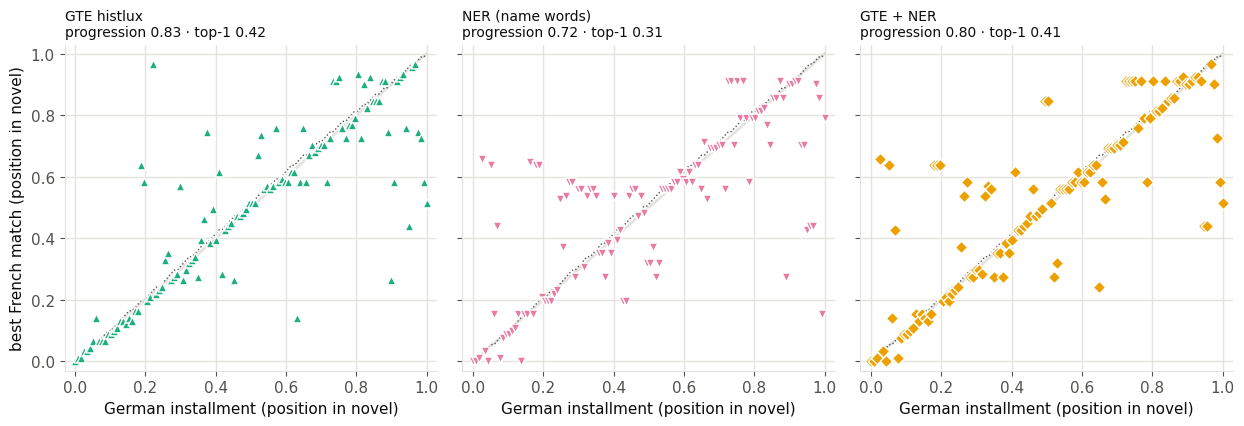

In [4]:
task = comparison[comparison["pair"] == "de vs fr"].set_index("feature")

def mapping_plot(shown):
    fig, axes = plt.subplots(1, len(shown), figsize=(4.2 * len(shown), 4.4), sharey=True)
    for ax, feature in zip(np.atleast_1d(axes), shown):
        row = task.loc[feature]
        style = STYLE[feature.replace(' (in order)', '')]
        n_de, n_fr = len(row["best"]), row["n_candidates"]
        x = np.arange(n_de) / (n_de - 1)
        ax.plot([0, 1], [0, 1], color=GRID, linewidth=2, zorder=0)
        ax.plot(x, np.array(row["expected"]) / (n_fr - 1), color=MUTED, linewidth=1, linestyle=":", zorder=1)
        ax.scatter(x, np.array(row["best"]) / (n_fr - 1), s=40, color=style["color"],
                   marker=style["marker"], edgecolor="white", linewidth=1, zorder=2)
        stat = (f"median error {row['median_error']:.0f}" if "in order" in feature
                else f"progression {row['progression']:.2f}")
        ax.set_title(f"{feature}\n{stat} · top-1 {row['top1']:.2f}",
                     loc="left", fontsize=10, color=INK)
        ax.set_xlabel("German installment (position in novel)")
        ax.set_xlim(-0.03, 1.03); ax.set_ylim(-0.03, 1.03)
        ax.grid(color=GRID, linewidth=1)
    np.atleast_1d(axes)[0].set_ylabel("best French match (position in novel)")
    fig.tight_layout()

mapping_plot(["GTE histlux", "NER (name words)", "GTE + NER"])

### The same, with the matches forced to stay in order

So far each German installment is matched on its own. Here the matches may only move forward through the French
(`align_in_order`, dynamic programming; several German installments may share a French one, and French ones may
be skipped). **Progression is 1 by construction here, so ignore it for these panels** and read top-1 and median error.

The mapping is saved in `features/mapping_de_fr.csv`.

Caution: the "right answer" here is relative position, which is itself approximate. All in-order variants reach
about the same top-1 (~0.6), and reading pairs shows errors on both sides: for some installments the alignment
is right and the position key wrong, for others the reverse (German 74-77 stick on one French installment).
A hand-checked set of anchors would give a firmer number.

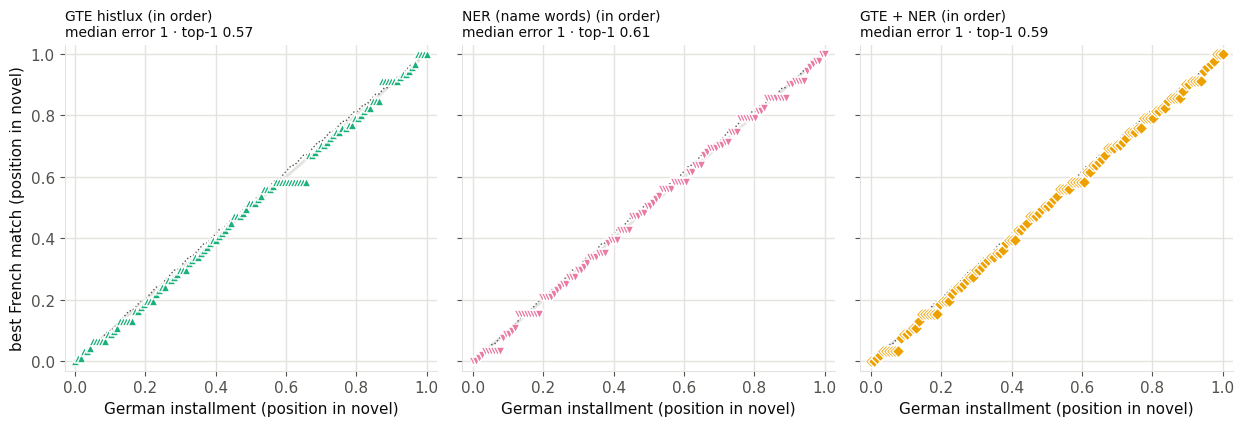

In [5]:
mapping_plot([f + " (in order)" for f in ["GTE histlux", "NER (name words)", "GTE + NER"]])

In [6]:
rows = ["GTE histlux", "NER (full names)", "NER (name words)", "GTE + NER"]
pd.DataFrame({
    "top-1 alone": task.loc[rows, "top1"].values,
    "top-1 in order": task.loc[[r + " (in order)" for r in rows], "top1"].values,
    "median error alone": task.loc[rows, "median_error"].values,
    "median error in order": task.loc[[r + " (in order)" for r in rows], "median_error"].values,
}, index=rows).round(2)

,top-1 alone,top-1 in order,median error alone,median error in order
GTE histlux,0.42,0.57,2.0,1.0
NER (full names),0.19,0.46,8.0,2.0
NER (name words),0.31,0.61,3.5,1.0
GTE + NER,0.41,0.59,2.0,1.0


## 3. How fast does each feature break under OCR noise?

We take the round-trip French (clean: Google fixed the OCR while translating), add simulated OCR noise
(`corrupt.py`: confused letters such as e/c, n/u, rn/m; lost accents; dropped letters; stray punctuation;
split and glued words) and match each corrupted installment back to the original French.

The shaded band is where Impresso's real OCR of this novel lies (its OCR-quality score 0.60–0.96,
translated to our noise scale with the same score).

In [7]:
levels = robustness.groupby("noise")["ocrqa"].first()
real = [json.loads(l)["ocrqa"] for l in open("secret_du_titan/fr.jsonl")
        if json.loads(l).get("ocr_source") == "impresso"]
# noise level that gives the same OCR-quality score (ocrqa falls as noise rises)
to_noise = lambda q: float(np.interp(-q, -levels.values, levels.index.values))
band = (to_noise(max(real)) * 100, to_noise(min(real)) * 100)
median = to_noise(float(np.median(real))) * 100
print(f"Impresso's real French OCR ≈ {band[0]:.1f}–{band[1]:.1f}% simulated noise (median {median:.1f}%)")
print(levels.rename("mean OCR-quality score").to_frame().T.round(2))

Impresso's real French OCR ≈ 0.3–9.3% simulated noise (median 1.4%)
noise                   0.000  0.010  0.020  0.030  0.050  0.075  0.100  \
mean OCR-quality score   0.98   0.91   0.85    0.8   0.72   0.64   0.58   

noise                   0.150  0.200  0.300  
mean OCR-quality score   0.49   0.43   0.36  


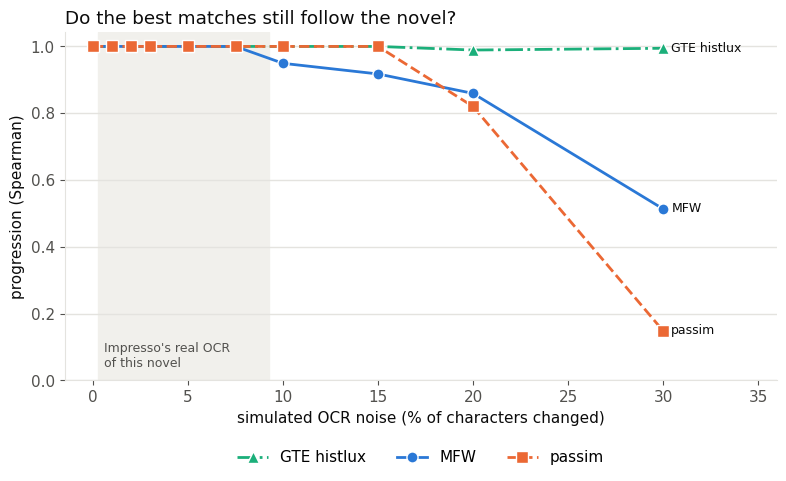

In [8]:
def decay_plot(measure, ylabel, title, relative=False):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.axvspan(*band, color="#f1f0ec", zorder=0)
    ax.text(band[0] + 0.3, 0.04, "Impresso's real OCR\nof this novel", color=MUTED, fontsize=9,
            transform=ax.get_xaxis_transform())
    for feature, rows in robustness.groupby("feature"):
        rows = rows.sort_values("noise")
        y = rows[measure] / rows[measure].iloc[0] if relative else rows[measure]
        ax.plot(rows["noise"] * 100, y, label=feature, linewidth=2, markersize=8,
                markeredgecolor="white", **STYLE[feature])
        ax.annotate(feature, (rows["noise"].iloc[-1] * 100, y.iloc[-1]), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=9, color=INK)
    ax.set_xlabel("simulated OCR noise (% of characters changed)")
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left", color=INK)
    ax.set_ylim(bottom=min(0, ax.get_ylim()[0]))
    ax.set_xlim(right=36)
    ax.grid(axis="y", color=GRID, linewidth=1)
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3)
    fig.tight_layout()
    return fig

decay_plot("progression", "progression (Spearman)",
           "Do the best matches still follow the novel?");

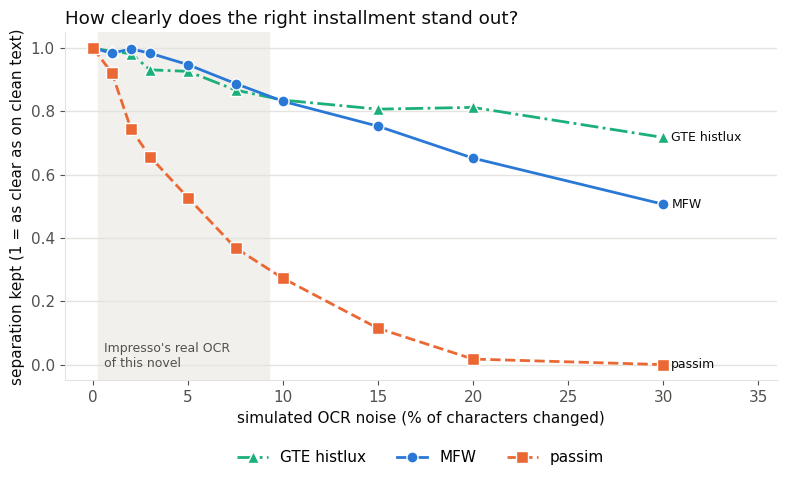

In [9]:
decay_plot("separation", "separation kept (1 = as clear as on clean text)",
           "How clearly does the right installment stand out?", relative=True);

In [10]:
print("the same numbers as a table (separation kept, 1 = as on clean text)")
sep = robustness.pivot_table(index="noise", columns="feature", values="separation")
(sep / sep.iloc[0]).round(2)

the same numbers as a table (separation kept, 1 = as on clean text)


feature,GTE histlux,MFW,passim
noise,,,
0.000,1.00,1.00,1.00
0.010,0.99,0.98,0.92
0.020,0.98,1.00,0.74
0.030,0.93,0.98,0.66
0.050,0.93,0.95,0.53
0.075,0.87,0.89,0.37
0.100,0.84,0.83,0.27
0.150,0.81,0.75,0.11
0.200,0.81,0.65,0.02
